In [37]:
#########
## SET UP
#########

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from fontTools.diff import color

# training data
X_train = pd.read_csv("projectA/projectA_train_expression.csv.gz")
y_train = pd.read_csv("projectA/projectA_train_metadata.csv")

# test data
X_test = pd.read_csv("projectA/projectA_test_expression.csv.gz")
test_metadata = pd.read_csv("projectA/projectA_test_metadata.csv")

# additional info
gene_annotation = pd.read_csv("projectA/projectA_gene_annotation.csv")
submission = pd.read_csv("projectA/projectA_submission_template.csv")


A1.1 Metadata table

In [277]:
#################
## METADATA TABLE
#################

# info
#print(y_train.head())
samples_per_woman = y_train['woman_id'].value_counts()
#print("Samples per woman:\n",samples_per_woman)

sample_mean = y_train['woman_id'].value_counts().mean()
print("Average sample size per woman:\n", round(sample_mean, 4))

mean_samples_per_group = y_train.groupby(["group", "woman_id"]).size().groupby("group").mean()

print("Average sample size by group:\n", mean_samples_per_group)

age_mean = y_train['gestational_age'].value_counts().mean()
print("Average gestational age:\n", round(age_mean, 4))

mean_age_per_group = y_train.groupby(["group", "gestational_age"]).size().groupby("group").mean()

print("Average gestational age by group:\n",
      mean_age_per_group)
#####################
## for visualisation:
samples_per_group = y_train.groupby(["group", "woman_id"]).size().groupby("group").value_counts()

age_per_group = y_train.groupby(["group", "gestational_age"]).size().groupby("group").value_counts()


Average sample size per woman:
 4.7051
Average sample size by group:
 group
Control               4.153846
Early_Preeclampsia    5.666667
PPROM                 5.411765
sPTD                  4.937500
dtype: float64
Average gestational age:
 2.1845
Average gestational age by group:
 group
Control               1.723404
Early_Preeclampsia    1.133333
PPROM                 1.295775
sPTD                  1.179104
dtype: float64


In [279]:
age_per_group.describe()

count    15.000000
mean     17.466667
std      20.608135
min       1.000000
25%       2.000000
50%       7.000000
75%      28.000000
max      58.000000
Name: count, dtype: float64

In [33]:
####################
## EXPLORATORY STATS
####################
print("X_train:\n",X_train.shape)

print("y_train:\n",y_train.shape)

## NAs
print(X_train.isna().sum().sum())
print(y_train.isna().sum())
# no NAs in data

## check if every sample can be identified in X_train
print(set(X_train["sample_id"]) == set(y_train["sample_id"]))
# true

X_train:
 (367, 32831)
y_train:
 (367, 5)
0
sample_id          0
woman_id           0
batch              0
group              0
gestational_age    0
dtype: int64


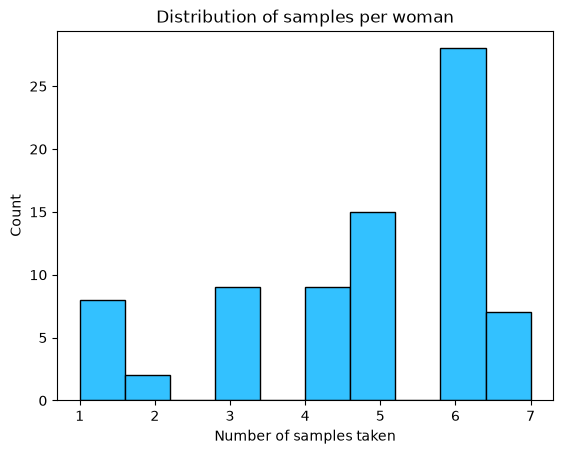

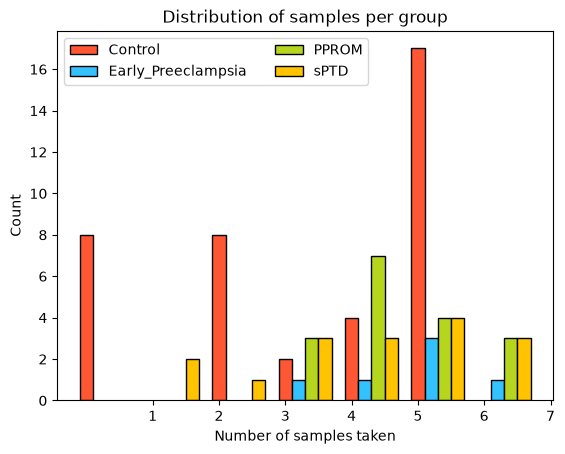

Index(['Control', 'Early_Preeclampsia', 'PPROM', 'sPTD'], dtype='str',
      name='group')


In [287]:
#################
## VISUALISATIONS
#################
## samples per woman
plt.figure()
plt.hist(samples_per_woman, color="#33C1FF", edgecolor="black")
plt.xlabel("Number of samples taken")
plt.ylabel("Count")
plt.title("Distribution of samples per woman")
plt.show()

## samples per group
group_samples_vis = samples_per_group.unstack(level=0)
group_cols = group_samples_vis.columns
group_index = group_samples_vis.index
x = np.arange(len(group_index))
width = 0.2

plt.figure()
plt.bar(x, group_samples_vis.iloc[:,0],width=width, label= group_cols[0], edgecolor="black", color="#FF5733")
plt.bar(x+width, group_samples_vis.iloc[:,1], width=width, label = group_cols[1], edgecolor="black", color="#33C1FF")
plt.bar(x+width*2, group_samples_vis.iloc[:,2], width=width, label = group_cols[2], edgecolor="black", color="#B6D51F")
plt.bar(x+width*3, group_samples_vis.iloc[:,3], width=width, label = group_cols[3], edgecolor="black", color="#FFC300")
plt.xticks(group_index)
plt.legend(loc='upper left', ncol=2)
plt.xlabel("Number of samples taken")
plt.ylabel("Count")
plt.title("Distribution of samples per group")
plt.show()

## ga range per group
print(group_age_vis.columns)


group  Control  Early_Preeclampsia  PPROM  sPTD
1         49.0                27.0   52.0  58.0


/tmp/ipykernel_9012/2047014570.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(group_age_vis[:1], vert=True)


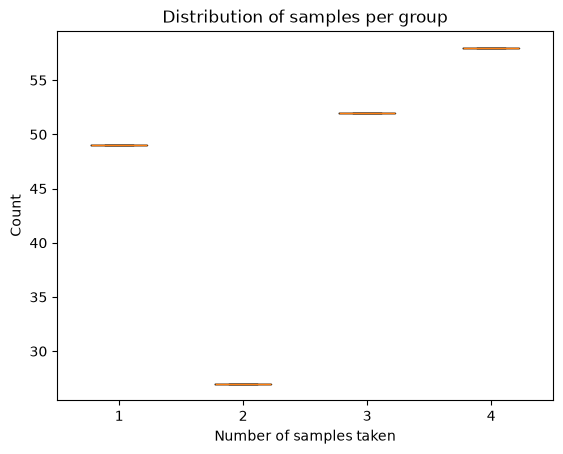

In [316]:
group_age_vis = age_per_group.unstack(level=0)

print(group_age_vis[:1])

plt.figure()
plt.boxplot(group_age_vis[:1], vert=True)
#plt.xticks(group_index)
#plt.legend(loc='upper left', ncol=2)
plt.xlabel("Number of samples taken")
plt.ylabel("Count")
plt.title("Distribution of samples per group")
plt.show()

In [34]:
################
## DATA OVERVIEW
################

## dimensions
print(X_train.shape)
print(y_train.shape)
#print(X_test.shape)
#print(test_metadata.shape)

## overview
#print(X_train.head()) ## GA values per sample + gene
#print(y_train.head()) ## woman ID + sample ID + info
#print(y_train.info())
#print(y_train.describe(include="all"))

(367, 32831)
(367, 5)
True


In [7]:
# Number of samples
print("Number of samples:", len(y_train))

# Number of unique women
print("Number of unique woman:", y_train["woman_id"].nunique())

# Number of samples per woman
print("Samples per woman", y_train["woman_id"].value_counts())

print("Samples:", y_train["woman_id"].value_counts().describe())
## 50%: 5

# Distribution of gestational age
print("Gestational age:", y_train["gestational_age"].describe())

# Distribution of groups
print("Groups:", y_train["group"].value_counts())

# Distribution of batches
print("batches:", y_train["batch"].value_counts())

# Number of samples per woman and group
samples_per_woman = (
    y_train.groupby(["group", "woman_id"])["sample_id"]
    .nunique()
    .reset_index(name="n_samples")
)

# Average samples per woman per group
print(samples_per_woman.groupby("group")["n_samples"].mean())

Number of samples: 367
Number of unique woman: 78
Samples per woman woman_id
W047    7
W082    7
W049    7
W064    7
W107    7
       ..
W138    1
W073    1
W076    1
W096    1
W023    1
Name: count, Length: 78, dtype: int64
Samples: count    78.000000
mean      4.705128
std       1.766271
min       1.000000
25%       4.000000
50%       5.000000
75%       6.000000
max       7.000000
Name: count, dtype: float64
Gestational age: count    367.000000
mean      26.060218
std        8.390041
min        9.100000
25%       19.400000
50%       26.400000
75%       33.200000
max       40.300000
Name: gestational_age, dtype: float64
Groups: group
Control               162
PPROM                  92
sPTD                   79
Early_Preeclampsia     34
Name: count, dtype: int64
batches: batch
4     49
7     48
2     38
10    38
6     37
1     33
32    32
3     32
8     28
9     25
5      7
Name: count, dtype: int64
group
Control               4.153846
Early_Preeclampsia    5.666667
PPROM              